# Week 1: What does a report representation contain?

See `week1/README.md` for the task. This notebook works through the steps in order.

## Setup

The notebook starts inside `week1/`, but `src/` and `data/` live one folder up in `Project3/`. We move there once, so `import src` and the `data/...` paths work.

In [2]:
import os
import sys
from pathlib import Path

if Path.cwd().name == "week1":  # only move up once, even if this cell is re-run
    os.chdir("..")
sys.path.insert(0, ".")  # make `src` importable

from src.data import findings_texts, study_table
from src.embeddings import embedding_path, load_embeddings

/Users/KAROLINE/Desktop/RAI/Project3/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Step 2: load the representation

`scripts/make_embeddings.py` has already run frozen BioClinicalBERT over the Findings of every study, averaged the token vectors (mean pooling) and saved one 768-value vector per study in `data/embeddings/`.

Row `i` of `X` belongs to row `i` of `studies`; `load_embeddings` checks this.

In [3]:
studies = study_table()                                   # one row per study
X = load_embeddings(embedding_path("findings"), studies)  # one vector per study

print("studies:", studies.shape)
print("X:", X.shape)

studies: (10000, 47)
X: (10000, 768)


In [9]:
studies.head(5)
#studies[0:5]
#X[0,3]

,study_id,patient_id,accession_number,study_uid,series_uid,image_id,image_path,n_images_in_study,sex,age_years,...,chexbert_atelectasis,chexbert_pneumothorax,chexbert_pleural_effusion,chexbert_pleural_other,chexbert_fracture,chexbert_support_devices,chexbert_no_finding,health_system,findings_words,impression_words
0,pGRDN00F50ZHP2J37_aGRDN4NZ04L5NOJRG_s1.2.826.0...,GRDN00F50ZHP2J37,GRDN4NZ04L5NOJRG,1.2.826.0.1.3680043.8.498.50766506393885586908...,1.2.826.0.1.3680043.8.498.12527569567674695009...,1.2.826.0.1.3680043.8.498.57624507441679557090...,deid_png/GRDN00F50ZHP2J37/GRDN4NZ04L5NOJRG/stu...,2,F,2.916667,...,blank,blank,blank,blank,blank,blank,no,thryothor-495511,39,7
1,pGRDN00LAM902RO0A_aGRDNYU9P2CFGLYNY_s1.2.826.0...,GRDN00LAM902RO0A,GRDNYU9P2CFGLYNY,1.2.826.0.1.3680043.8.498.56198826287585471417...,1.2.826.0.1.3680043.8.498.35211439685735792344...,1.2.826.0.1.3680043.8.498.39422455539300242621...,deid_png/GRDN00LAM902RO0A/GRDNYU9P2CFGLYNY/stu...,2,M,63.000000,...,blank,blank,blank,blank,blank,blank,no,thryothor-495511,33,8
2,pGRDN00PW30IBG1U6_aGRDN2B266YUFRYK2_s1.2.826.0...,GRDN00PW30IBG1U6,GRDN2B266YUFRYK2,1.2.826.0.1.3680043.8.498.68345424877713419914...,1.2.826.0.1.3680043.8.498.17208040682034961990...,1.2.826.0.1.3680043.8.498.42018266953557089750...,deid_png/GRDN00PW30IBG1U6/GRDN2B266YUFRYK2/stu...,2,M,NaN,...,blank,blank,blank,blank,blank,blank,yes,tachyeres-387144,32,3
3,pGRDN00PW30IBG1U6_aGRDNDRVSP1696HHL_s1.2.826.0...,GRDN00PW30IBG1U6,GRDNDRVSP1696HHL,1.2.826.0.1.3680043.8.498.84960780901675888912...,1.2.826.0.1.3680043.8.498.79318339948701390282...,1.2.826.0.1.3680043.8.498.19176710663760530814...,deid_png/GRDN00PW30IBG1U6/GRDNDRVSP1696HHL/stu...,1,M,NaN,...,blank,blank,blank,blank,blank,blank,yes,tachyeres-387144,25,3
4,pGRDN00SZ4W5JTK30_aGRDN88LU52Q4GM08_s1.2.826.0...,GRDN00SZ4W5JTK30,GRDN88LU52Q4GM08,1.2.826.0.1.3680043.8.498.93341659656577920063...,1.2.826.0.1.3680043.8.498.94560927545241797951...,1.2.826.0.1.3680043.8.498.95233093512266400820...,deid_png/GRDN00SZ4W5JTK30/GRDN88LU52Q4GM08/stu...,1,M,44.000000,...,blank,positive,blank,blank,blank,blank,no,thryothor-495511,42,25


Look at one study: its text, and the first numbers of the vector that stands for it.

In [4]:
i = 0
print(findings_texts(studies)[i])
print(X[i, :10])

Cardiac silhouette, mediastinal, and hilar contours are within normal limits. There is mild peribronchial thickening in the perihilar regions and some minimal streaky areas of atelectasis. Findings suggest viral bronchiolitis. No focal infiltrates. No effusions. Bony structures are intact.
[ 0.18298787 -0.4405664   0.09515159  0.45542708  0.2033642  -0.09014548
 -0.06911324  0.02800336  0.03655485  0.1509264 ]


## Step 3: look at the representation with UMAP

UMAP squeezes the 768 values of each study into 2, so every study becomes a point. Studies that are close in the representation end up close in the picture.

`n_neighbors` = how many neighbours UMAP looks at when placing a point: small = local detail (many islands), large = global shape.

This cell takes about 2 minutes (most of it for 200). Warnings about *spectral initialisation failed* are harmless: about 1,000 reports have the exact same text, so they get the exact same vector, and UMAP falls back to a random start.

In [12]:
import matplotlib.pyplot as plt
import pandas as pd
import umap

from src.data import binary_label, top_k_classes

umaps = {}  # n_neighbors -> (10000, 2) array of 2D points
for n in [5, 15, 200]:
    umaps[n] = umap.UMAP(n_neighbors=n, random_state=0).fit_transform(X)
    print("done:", n)

/Users/KAROLINE/Desktop/RAI/Project3/.venv/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/Users/KAROLINE/Desktop/RAI/Project3/.venv/lib/python3.14/site-packages/umap/spectral.py:548: UserWarning: Spectral initialisation failed! The eigenvector solver
failed. This is likely due to too small an eigengap. Consider
adding some noise or jitter to your data.

Falling back to random initialisation!
  warn(
/Users/KAROLINE/Desktop/RAI/Project3/.venv/lib/python3.14/site-packages/umap/spectral.py:548: UserWarning: Spectral initialisation failed! The eigenvector solver
failed. This is likely due to too small an eigengap. Consider
adding some noise or jitter to your data.

Falling back to random initialisation!
  warn(
/Users/KAROLINE/Desktop/RAI/Project3/.venv/lib/python3.14/site-packages/umap/spectral.py:548: UserWarning: Spectral initialisation failed! The eigenvector solver
failed. This

done: 5


/Users/KAROLINE/Desktop/RAI/Project3/.venv/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


done: 15


/Users/KAROLINE/Desktop/RAI/Project3/.venv/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


done: 200


A small helper to draw one coloured UMAP picture. Missing values (e.g. uncertain labels) are drawn in grey underneath.
- few distinct values (labels, health system): one colour per class + legend
- many distinct values (age, year, length): a colour scale

In [13]:
def plot_umap(ax, points, values, title):
    values = pd.Series(values).reset_index(drop=True)
    known = values.notna().to_numpy()
    ax.scatter(*points[~known].T, s=1, c="lightgrey")
    if pd.api.types.is_numeric_dtype(values) and values.nunique() > 10:
        dots = ax.scatter(*points[known].T, s=1, c=values[known], cmap="viridis")
        plt.colorbar(dots, ax=ax)
    else:
        for cls in sorted(values[known].unique()):
            ax.scatter(*points[(values == cls).to_numpy()].T, s=1, label=cls)
        ax.legend(markerscale=6, fontsize=8)
    ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks([])

### 3a: the effect of `n_neighbors`

Same data, three settings, coloured by edema (clear cases only, the rest grey).

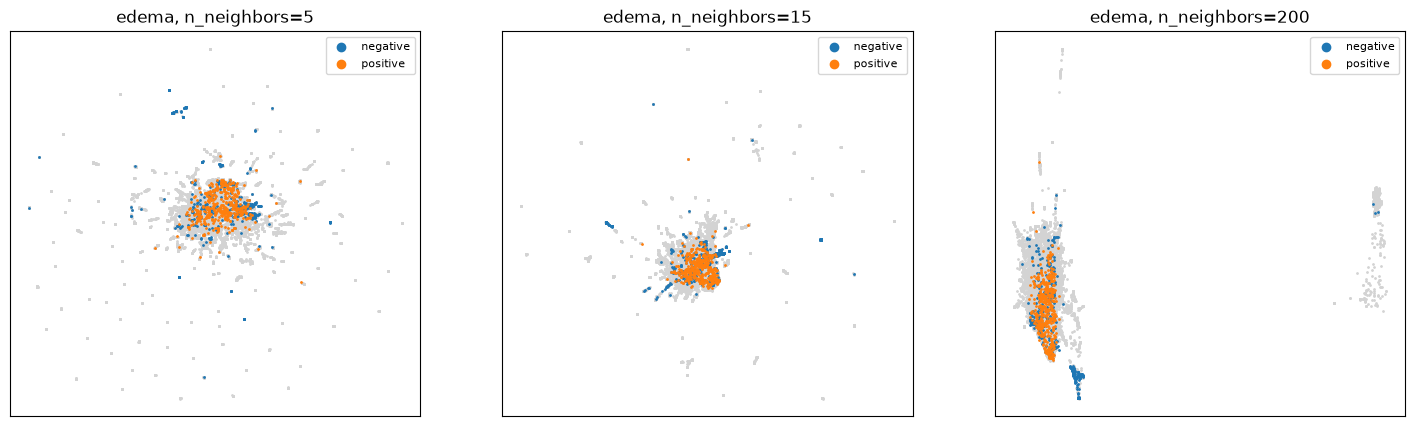

In [14]:
edema = binary_label(studies, "edema").map({1: "positive", 0: "negative"})

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, n in zip(axes, umaps):
    plot_umap(ax, umaps[n], edema, f"edema, n_neighbors={n}")
plt.show()

### 3b: what do the groups follow?

Default picture (`n_neighbors=15`), coloured by the two diseases and then by metadata. Do the groups follow the diseases, or something else?

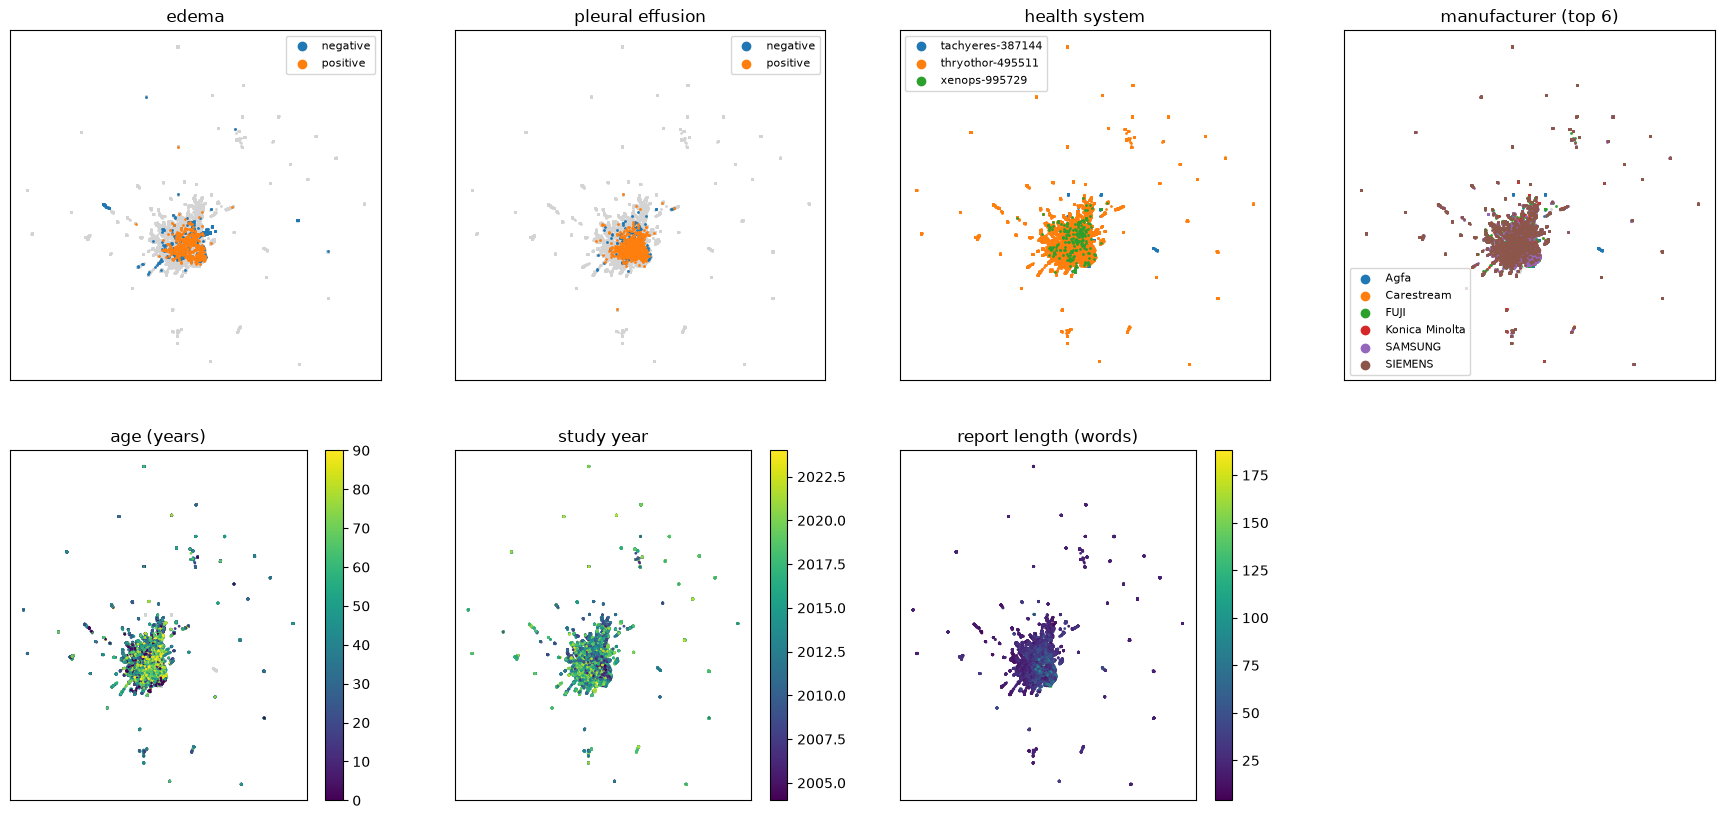

In [15]:
targets = {
    "edema": edema,
    "pleural effusion": binary_label(studies, "pleural_effusion").map({1: "positive", 0: "negative"}),
    "health system": studies["health_system"],
    "manufacturer (top 6)": top_k_classes(studies["manufacturer"], 6),
    "age (years)": studies["age_years"],
    "study year": studies["study_year"],
    "report length (words)": studies["findings_words"],
}

fig, axes = plt.subplots(2, 4, figsize=(22, 10))
for ax, (name, values) in zip(axes.flat, targets.items()):
    plot_umap(ax, umaps[15], values, name)
axes.flat[-1].axis("off")  # 7 pictures, 8 slots
plt.show()

### 3c: cosine instead of straight-line distance

Default UMAP compares vectors by straight-line (euclidean) distance. `metric="cosine"` compares only their *direction*, ignoring their length. Same settings otherwise, coloured by edema. Takes about 30 seconds.

/Users/KAROLINE/Desktop/RAI/Project3/.venv/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


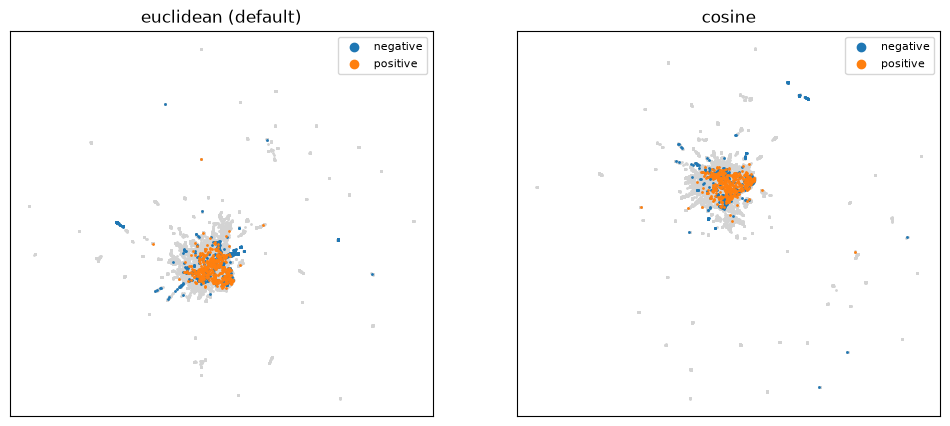

In [16]:
umap_cosine = umap.UMAP(n_neighbors=15, metric="cosine", random_state=0).fit_transform(X)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
plot_umap(axes[0], umaps[15], edema, "euclidean (default)")
plot_umap(axes[1], umap_cosine, edema, "cosine")
plt.show()

## Step 4: measure with linear probes

A **linear probe** is a logistic regression that predicts one target from the 768 values. If it predicts well on studies it has not seen, the information is in the representation.

**Patient-wise evaluation:** `StratifiedGroupKFold` splits the studies into 5 folds so that all studies of one patient are in the same fold. Otherwise the probe could recognise the *patient* instead of the disease.

For each fold we train on the other 4 folds and predict the held-out one. At the end every study has one test prediction, and we compute one AUROC on all of them (0.5 = guessing, 1.0 = perfect).

In [17]:
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from src.data import usable_findings


def probe_auroc(model, features, y, groups):
    probs = np.zeros(len(y))
    folds = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=0)
    for train, test in folds.split(features, y, groups):
        model.fit(features[train], y[train])                         # train on 4 folds
        probs[test] = model.predict_proba(features[test])[:, 1]      # predict the 5th
    return roc_auc_score(y, probs)

Two probes:
- **BioClinicalBERT:** standardise the 768 values, then logistic regression.
- **TF-IDF baseline:** describe each report only by its words and word pairs, then logistic regression. Because the vectoriser is inside the pipeline, it is re-fitted on the training folds only, so no test words leak into the vocabulary.

Only studies with a clear label (positive/negative) are used.

In [18]:
bert_probe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
tfidf_probe = make_pipeline(TfidfVectorizer(ngram_range=(1, 2)), LogisticRegression(max_iter=1000))
texts = np.array(findings_texts(studies), dtype=object)  # array, so it can be indexed like X

for obs in ["edema", "pleural_effusion"]:
    label = binary_label(studies, obs)
    keep = (usable_findings(studies) & label.notna()).to_numpy()
    y = label[keep].to_numpy().astype(int)
    groups = studies.loc[keep, "patient_id"].to_numpy()

    bert = probe_auroc(bert_probe, X[keep], y, groups)
    tfidf = probe_auroc(tfidf_probe, texts[keep], y, groups)
    print(f"{obs:17s} n={keep.sum()}  BERT AUROC={bert:.3f}  TF-IDF AUROC={tfidf:.3f}")

edema             n=851  BERT AUROC=0.919  TF-IDF AUROC=0.946
pleural_effusion  n=784  BERT AUROC=0.914  TF-IDF AUROC=0.928


## Step 5: what else is in there?

Same idea as step 4, but now the targets are metadata. The *kind* of target decides model, split and score:

| Kind | Model | Split | Score | Chance |
|---|---|---|---|---|
| yes/no | logistic regression | `StratifiedGroupKFold` | AUROC | 0.5 |
| classes | logistic regression | `StratifiedGroupKFold` | balanced accuracy | 1 / number of classes |
| number | ridge regression | `GroupKFold` | R² | 0 |

`probe` below is `probe_auroc` from step 4, extended to handle all three kinds.

In [19]:
from sklearn.linear_model import Ridge
from sklearn.metrics import balanced_accuracy_score, r2_score
from sklearn.model_selection import GroupKFold


def probe(model, features, y, groups, kind):
    if kind == "number":
        folds = GroupKFold(n_splits=5)
    else:
        folds = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=0)
    preds = np.zeros(len(y))
    for train, test in folds.split(features, y, groups):
        model.fit(features[train], y[train])
        if kind == "yes/no":
            preds[test] = model.predict_proba(features[test])[:, 1]  # probability, for AUROC
        else:
            preds[test] = model.predict(features[test])              # class or number
    if kind == "yes/no":
        return roc_auc_score(y, preds)
    if kind == "classes":
        return balanced_accuracy_score(y, preds)
    return r2_score(y, preds)


def new_head(kind):
    return Ridge() if kind == "number" else LogisticRegression(max_iter=1000)

One target of each kind. To try others, add lines to `targets`, e.g.
`"manufacturer": (top_k_classes(studies["manufacturer"], 6), "classes")` or `"study year": (studies["study_year"], "number")`.

Studies with a missing value are dropped (sex `O` becomes missing via `.map`). For classes, `pd.factorize` turns the names into numbers 0, 1, 2, ...

In [21]:
targets = {
    "sex (F vs M)": (studies["sex"].map({"F": 1, "M": 0}), "yes/no"),
    "health system": (studies["health_system"], "classes"),
    "age (years)": (studies["age_years"], "number"),
    "study year": (studies["study_year"], "number"),
    "report length (words)": (studies["findings_words"], "number"),
    "manufacturer (top 6)": (top_k_classes(studies["manufacturer"], 6), "classes"),
}

for name, (values, kind) in targets.items():
    keep = (usable_findings(studies) & values.notna()).to_numpy()
    y = pd.factorize(values[keep])[0] if kind == "classes" else values[keep].to_numpy()
    groups = studies.loc[keep, "patient_id"].to_numpy()

    bert = probe(make_pipeline(StandardScaler(), new_head(kind)), X[keep], y, groups, kind)
    tfidf = probe(make_pipeline(TfidfVectorizer(ngram_range=(1, 2)), new_head(kind)), texts[keep], y, groups, kind)
    print(f"{name:15s} {kind:8s} n={keep.sum()}  BERT={bert:.3f}  TF-IDF={tfidf:.3f}")

sex (F vs M)    yes/no   n=9870  BERT=0.545  TF-IDF=0.557
health system   classes  n=10000  BERT=0.680  TF-IDF=0.508
age (years)     number   n=9582  BERT=0.430  TF-IDF=0.506
study year      number   n=10000  BERT=0.338  TF-IDF=0.474
report length (words) number   n=10000  BERT=0.960  TF-IDF=0.835
manufacturer (top 6) classes  n=9271  BERT=0.438  TF-IDF=0.456


Where age is hiding: some findings are typical of age.

Old: "degenerative changes of the spine", "atherosclerotic aorta", "enlarged heart".
Young: "peribronchial thickening… viral bronchiolitis", which is typical in children. That's exactly study 0 from step 2.

This matches the UMAP picture, where older patients were in the core with the longer, sicker reports. So the text never states the age, but the medical content gives it away.

Why this matters for Responsible AI: information you never asked for, like the hospital or the age, is in the vector, and any model built on it can use it.

 Why BERT beats TF-IDF on health system. Hospitals don't write their name in the report, but each one has its own writing style: report templates, phrasing, the order of sentences. BERT's average captures that overall style, while TF-IDF only counts individual words, and many words are shared between hospitals.
Example: in one hospital the template "The heart size and mediastinal contours are within normal limits. Both lungs are clear." appears 1,003 times. Another hospital might write "Heart normal. Lungs clear." Same meaning, different style, and BERT picks up on that.

A second reason: 93% of the studies come from one system, and balanced accuracy punishes a probe that mostly guesses that one. TF-IDF probably leans that way more. That's a guess; you could check it later.

## Step 6: interpret

Write a few sentences per question in your own words. The bullets are reminders of what we saw.

**1. What does the probe find that the UMAP picture does not show, or the other way round?**
- UMAP: diseases, age and report length all sit in the core of the blob; health system was hard to see (one system has 93% of the studies).
- Probes: health system is clearly present (0.68 vs chance 0.33), even though the picture barely showed it.

*Your answer:*

**2. Where do TF-IDF and BioClinicalBERT differ, and why?**
- Edema / effusion: TF-IDF slightly better (0.946 vs 0.919).
- Health system: BERT much better (0.68 vs 0.51).

*Your answer:*

**3. What could the metadata in the representation mean for a model built on it?**
- Health system and age are in there, sex barely.

*Your answer:*